## 1. Before You Begin

**When is a probability confident enough to act on?** A decision model hands back numbers, and our code has to turn them into actions. In this notebook we run a whole shift of messages at the Contoso Music Festival ops desk, the story from the [capsule README](README.md), and check whether the model's confidence matches how often it's right. Then we set thresholds that sort every decision into an automatic, queued, or human lane, and choose them by what each mistake costs.

![Site map of the fictional Contoso Music Festival](assets/contoso-music-festival-map.png)

| Detail | Value |
|---|---|
| Model card | [Microsoft-Decision-1 — Foundry catalog](https://ai.azure.com/catalog/models/Microsoft-Decision-1) |
| Docs | [Deploy and use Microsoft-Decision-1](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-microsoft-decision) |
| Pricing | See the Pricing tab on the model card |
| Released | 2026-10-09 |
| Background | [Decision models primer](../../../docs/primers/decision-models.md) |

**Prerequisites**

1. A Microsoft Foundry project with Microsoft-Decision-1 deployed. See [models/quickstart/](../../quickstart/README.md) for first-time setup, then run `./scripts/3-deploy-model.sh decision-1 Microsoft-Decision-1 --env-var AZURE_DECISION_1_DEPLOYMENT`.
2. The environment variables listed in section 2.
3. `requests`, `python-dotenv`, `pandas`, and `matplotlib` installed. The next cell installs them.

This notebook runs on its own. [Notebook 01](01-triage-festival-messages.ipynb) introduces the three question types, so it helps to have seen it first.

> This notebook sends about 150 short requests: one pass over the 74 messages, and a second pass in section 11. On a small deployment, that takes a minute or two for each pass.

## 2. Verify your environment

The cell below checks the three variables this notebook needs and builds the decision endpoint, `<resource>/providers/microsoft/v1/systemone`. It makes no paid request.

In [1]:
%pip install requests python-dotenv pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
from dotenv import load_dotenv
load_dotenv()

import os
from urllib.parse import urlparse

# Your .env file needs these variables:
#   MICROSOFT_FOUNDRY_ENDPOINT=https://<resource>.services.ai.azure.com/api/projects/<project>
#   MICROSOFT_FOUNDRY_API_KEY=<your key>
#   AZURE_DECISION_1_DEPLOYMENT=<your Microsoft-Decision-1 deployment name>
REQUIRED = {
    "MICROSOFT_FOUNDRY_ENDPOINT": "Foundry project endpoint",
    "MICROSOFT_FOUNDRY_API_KEY": "Foundry API key",
    "AZURE_DECISION_1_DEPLOYMENT": "Microsoft-Decision-1 deployment name",
}
missing = [name for name in REQUIRED if not os.environ.get(name)]
if missing:
    raise EnvironmentError(
        f"Set these in your .env file before continuing: {missing}. "
        "See models/quickstart/README.md, then deploy the model with "
        "./scripts/3-deploy-model.sh decision-1 Microsoft-Decision-1 --env-var AZURE_DECISION_1_DEPLOYMENT"
    )

parsed = urlparse(os.environ["MICROSOFT_FOUNDRY_ENDPOINT"])
DECISION_URL = f"{parsed.scheme}://{parsed.netloc}/providers/microsoft/v1/systemone"
API_KEY = os.environ["MICROSOFT_FOUNDRY_API_KEY"]
DEPLOYMENT = os.environ["AZURE_DECISION_1_DEPLOYMENT"]

print(f"Deployment : {DEPLOYMENT}")
print("Environment check passed.")

Deployment : Decision-1
Environment check passed.


## 3. Frame the question

At 18:05 a storm cell reaches the site. Between 15:05 and 18:24 the desk receives 74 messages, and it can't read every one with full attention. For each message the model returns a team, a severity, and a danger probability. What should happen next?

We'll sort each decision into one of three lanes:

| Lane | What happens | Who it's for |
|---|---|---|
| **auto** | The message goes to the team now, without anyone looking | Confident, low-risk decisions |
| **queue** | A dispatcher reviews it soon | Decisions the model is less sure about |
| **human** | A person decides right now | Possible danger, serious situations, and anything the model can't place |

The result we're looking for is a table that shows how many messages each lane handles, and one number that matters most: **how many real emergencies end up outside the human lane**. We want that number to be zero.

## 4. Configure the client

The same helpers as notebook 01. `decide` sends one request and retries with backoff on `429 Too Many Requests`. `decide_many` runs requests in parallel and keeps the answers in input order.

In [3]:
import json, time
import concurrent.futures
from pathlib import Path

import requests

ASSETS = Path("assets")
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

MAX_WORKERS = 4   # a capacity-1 deployment returned 429 responses at eight workers


def decide(state, questions, retries=6):
    """POST one decision request and return the parsed JSON response."""
    body = {"model": DEPLOYMENT, "state": state, "questions": questions}
    for attempt in range(retries):
        response = requests.post(
            DECISION_URL,
            headers={"api-key": API_KEY, "Content-Type": "application/json"},
            json=body,
            timeout=60,
        )
        if response.status_code == 429:   # rate limited: wait, then try again
            time.sleep(float(response.headers.get("Retry-After", 0)) or 1.5 * 2 ** min(attempt, 4))
            continue
        if not response.ok:
            raise requests.HTTPError(f"{response.status_code} {response.reason}: {response.text}", response=response)
        return response.json()
    raise RuntimeError("Still rate limited after several retries. Lower MAX_WORKERS or raise the deployment capacity.")


def decide_many(jobs, workers=MAX_WORKERS):
    """Run (state, questions) jobs in parallel; responses come back in input order."""
    with concurrent.futures.ThreadPoolExecutor(max_workers=workers) as executor:
        return list(executor.map(lambda job: decide(*job), jobs))


def bar(p, width=20):
    filled = round(p * width)
    return "█" * filled + "·" * (width - filled)

## 5. Run the whole shift

We ask the same four questions of every message: which team, how severe, is anyone in danger, and, when the desk already has open incidents, is this a repeat. The options are the ones notebook 01 ended with, including an `unclear` option so vague messages have somewhere to go.

The labels in `messages.json` are our own answers for each message. We use them to check the model, and the model never sees them.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 50)

MESSAGES = json.loads((ASSETS / "messages.json").read_text(encoding="utf-8"))

TEAMS = {
    "medical": "Injuries, illness, allergic reactions, heat or cold exposure, and requests for the medical tent",
    "security": "Fights, theft, weapons, fire, suspicious items or people, missing children, and crowd-control problems",
    "facilities": "Site infrastructure: stage and rigging, power, lighting, water, toilets, trash, tents, signage, and showers",
    "transport": "Shuttles, buses, parking, rideshare pickup, bikes, and traffic around the site",
    "guest_services": "Tickets, wristbands, refunds, lost property, accessibility, charging lockers, general questions, and feedback",
    "vendors": "Food and merchandise stalls: prices, food quality, hygiene, supplies, and stall equipment",
    "command": "Weather and site-wide decisions: lightning, wind, evacuation, shelter, show holds, and opening or closing gates",
    "unclear": "Not enough information to choose a team, or the message does not describe a specific problem",
}

SEVERITY_LEVELS = [
    "Routine: a question, feedback, or a minor annoyance",
    "Needs attention: a problem a team should fix soon",
    "Urgent: a safety risk or a fast-growing problem",
    "Emergency: someone may be seriously hurt right now",
]


def make_state(message):
    state = {"channel": message["channel"], "zone": message["zone"], "time": message["time"], "message": message["text"]}
    if message.get("open_incidents"):
        state["open_incidents"] = message["open_incidents"]
    return state


def make_questions(teams, with_repeat=False):
    questions = {
        "team": {"type": "choice", "instructions": "Which team should handle this message?", "criteria": teams},
        "severity": {"type": "score", "instructions": "How severe is the situation described?", "criteria": SEVERITY_LEVELS},
        "danger": {
            "type": "noul",
            "instructions": "Does the message describe a person who may be seriously hurt or in immediate physical danger right now?",
            "criteria": {
                "true": "Someone is or may be in immediate physical danger",
                "false": "No one is described as being in immediate danger",
            },
        },
    }
    if with_repeat:
        questions["repeat"] = {
            "type": "noul",
            "instructions": "Does this message report the same problem as one of the open incidents?",
        }
    return questions


def run_shift(teams):
    """Decide every message and return one row per message, next to our own labels."""
    jobs = [(make_state(m), make_questions(teams, bool(m.get("open_incidents")))) for m in MESSAGES]
    rows = []
    for message, response in zip(MESSAGES, decide_many(jobs)):
        answers, expected = response["answers"], message["expected"]
        hours, minutes = message["time"].split(":")
        rows.append({
            "id": message["id"],
            "time": message["time"],
            "minute": int(hours) * 60 + int(minutes),
            "text": message["text"],
            "expected": expected["team"],
            "team": answers["team"]["choice"],
            "conf": answers["team"]["confidence"],
            "sev": answers["severity"]["score"],
            "danger": answers["danger"]["noul"],
            "emergency": bool(expected["danger"]),   # our label: someone really was in danger
        })
    shift = pd.DataFrame(rows)
    shift["right"] = shift.team == shift.expected
    return shift


t0 = time.perf_counter()
shift = run_shift(TEAMS)
print(f"Decided {len(shift)} messages in {time.perf_counter() - t0:.0f}s")
print(f"Team accuracy: {shift.right.mean():.0%}   Emergencies in our labels: {shift.emergency.sum()}")
shift[["id", "time", "expected", "team", "conf", "sev", "danger"]].head(8).round(2)

Decided 74 messages in 16s
Team accuracy: 92%   Emergencies in our labels: 17


,id,time,expected,team,conf,sev,danger
0,m01,15:05,unclear,unclear,0.99,0.00,0.0
1,m02,15:12,guest_services,guest_services,0.99,0.85,0.0
2,m03,15:20,guest_services,guest_services,0.99,0.02,0.0
3,m04,15:31,guest_services,guest_services,1.00,0.11,0.0
4,m05,15:35,transport,transport,0.91,0.00,0.0
5,m06,15:40,facilities,facilities,0.99,0.03,0.0
6,m07,15:48,vendors,vendors,0.99,0.66,0.0
7,m08,15:55,facilities,facilities,0.99,1.00,0.0


## 6. Observe: does confidence match accuracy?

A probability is only useful if it means something. If the model says 0.95, it should be right about 95 times out of 100. We group the messages by how confident the model was and measure how often each group was right. Each bar below is one group, and a model whose confidence matched its accuracy would put every bar level with its own label.

The groups are small, so we read the pattern and not each exact value.

             messages  mean_confidence  accuracy
bucket                                          
< 0.70              5             0.55      0.40
0.70 – 0.90         3             0.86      0.33
0.90 – 0.97        11             0.95      0.91
0.97 – 1.00        55             0.99      1.00


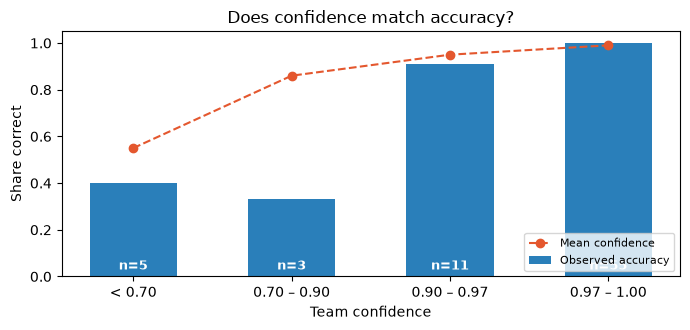

In [5]:
bins = [0, 0.7, 0.9, 0.97, 1.0001]
labels = ["< 0.70", "0.70 – 0.90", "0.90 – 0.97", "0.97 – 1.00"]
shift["bucket"] = pd.cut(shift.conf, bins=bins, labels=labels, right=False)

calibration = (
    shift.groupby("bucket", observed=True)
    .agg(messages=("id", "count"), mean_confidence=("conf", "mean"), accuracy=("right", "mean"))
    .round(2)
)
print(calibration)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(calibration.index.astype(str), calibration.accuracy, color="#2A7FBA", width=0.55, label="Observed accuracy")
ax.plot(calibration.index.astype(str), calibration.mean_confidence, "o--", color="#E4572E", label="Mean confidence")
for x, (_, row) in enumerate(calibration.iterrows()):
    ax.text(x, 0.03, f"n={int(row.messages)}", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Share correct")
ax.set_xlabel("Team confidence")
ax.set_title("Does confidence match accuracy?")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### 6.1 Read it

In the top group the model was confident and right on every message, which is what we'd hope. Accuracy is highest where confidence is highest and much lower below 0.9, so the confidence carries real signal. The lower groups have few messages, so they show a trend more than a rate.

Probabilities can shift a little when we send the same request again, so the exact values in these tables may differ slightly from run to run. The wrong answers are listed next. Two of them, `m57` and `m74`, were wrong with confidence close to the 0.9 mark, and we'll come back to both.

In [6]:
shift[~shift.right][["id", "time", "expected", "team", "conf", "text"]].round(2).assign(text=lambda d: d.text.str[:58])

,id,time,expected,team,conf,text
44,m45,17:42,guest_services,unclear,0.66,"Loving the lantern parade, thank you!"
52,m53,17:57,guest_services,security,0.55,"My son isn't lost anymore. Found him, sorry an..."
56,m57,18:02,vendors,facilities,0.95,Vendor 12's generator died. The freezer is ful...
62,m63,18:10,facilities,command,0.80,Tents are flooding and a few are blowing away ...
71,m72,18:20,facilities,unclear,0.35,Camping row C looks like a lake right now #Con...
73,m74,18:24,guest_services,command,0.89,Is Gate B still open? It looks closed and I ca...


## 7. Turn probabilities into lanes

Now we write the first rule. It's a short function of the numbers the model returns:

- **human** when the model thinks someone may be in danger (`danger` at 0.5 or above), picked `unclear`, or wasn't confident (`conf` below 0.7)
- **auto** when the team confidence is 0.9 or above
- **queue** for everything in between

It looks reasonable, and it uses the danger question the way its name suggests. Let's see how it does against the 17 messages we labeled as real emergencies.

In [7]:
def assign_lanes(df, auto_conf=0.9, danger_cut=0.5, severity_cut=None, low_conf=0.7):
    """Sort each decision into auto, queue, or human, using the model's probabilities."""
    needs_person = (df.danger >= danger_cut) | (df.team == "unclear") | (df.conf < low_conf)
    if severity_cut is not None:
        needs_person = needs_person | (df.sev >= severity_cut)
    return pd.Series(np.where(needs_person, "human", np.where(df.conf >= auto_conf, "auto", "queue")), index=df.index)


def summarize(df, lanes):
    auto = lanes == "auto"
    return {
        "auto": int(auto.sum()),
        "queue": int((lanes == "queue").sum()),
        "human": int((lanes == "human").sum()),
        "wrong in auto": int((auto & ~df.right).sum()),
        "emergencies missed": int(((lanes != "human") & df.emergency).sum()),
    }


shift["lane_v1"] = assign_lanes(shift)
summary_v1 = summarize(shift, shift.lane_v1)
print(pd.Series(summary_v1).to_string())
print()
print(pd.crosstab(shift.lane_v1, shift.emergency.map({True: "real emergency", False: "not an emergency"})))

auto                  42
queue                  2
human                 30
wrong in auto          1
emergencies missed     3

emergency  not an emergency  real emergency
lane_v1                                    
auto                     39               3
human                    16              14
queue                     2               0


## 8. Diagnose: which emergencies did the rule miss?

Some real emergencies are outside the human lane. That's the one outcome we said we couldn't accept, so we look at exactly which messages those are and what the model returned for them.

In [8]:
missed = shift[(shift.lane_v1 != "human") & shift.emergency]
missed[["id", "time", "team", "conf", "sev", "danger", "lane_v1", "text"]].round(2).assign(text=lambda d: d.text.str[:70])

,id,time,team,conf,sev,danger,lane_v1,text
34,m35,17:20,facilities,0.99,1.92,0.27,auto,Left speaker tower is leaning. Looks like the ...
50,m51,17:53,transport,0.99,2.73,0.44,auto,"Rideshare pickup is total chaos, cars are bloc..."
58,m59,18:05,command,1.00,1.95,0.18,auto,Wind gusts hitting 50 kilometres an hour at th...


The team and the confidence are fine. What stands out is `danger`, which is low for every missed message, while `sev` is high. Our `danger` question asks about "a person who may be seriously hurt right now." These messages describe hazards that haven't hurt anyone yet, such as a leaning speaker tower, a blocked rideshare lane, or gusts of 50 kilometres an hour. That's a different thing to the model, and it answered the question we asked.

So the hypothesis is that `severity` sees what `danger` doesn't. We can check it against the whole shift. If the missed messages score high on severity and most routine messages don't, a severity threshold can catch them.

In [9]:
print(f"Severity of the missed emergencies: {', '.join(f'{v:.2f}' for v in missed.sev)}")
print()
print(shift.groupby("emergency").sev.describe()[["count", "mean", "min", "25%", "50%", "75%", "max"]].round(2).rename(index={False: "not an emergency", True: "real emergency"}))

Severity of the missed emergencies: 1.92, 2.73, 1.95

                  count  mean   min   25%   50%   75%   max
emergency                                                  
not an emergency   57.0  1.00  0.00  0.15  1.00  1.56  2.66
real emergency     17.0  2.64  1.92  2.16  2.82  2.97  3.00


## 9. Fix and verify

We add one condition: send a message to a person when `severity` is 1.75 or above, whatever the danger probability says. 1.75 sits between "Needs attention" at 1 and "Urgent" at 2 on the scale. The danger and confidence rules stay the same, so we can compare before and after.

In [10]:
shift["lane_v2"] = assign_lanes(shift, severity_cut=1.75)

compare = pd.DataFrame({"danger and confidence only": summarize(shift, shift.lane_v1),
                        "plus severity at 1.75": summarize(shift, shift.lane_v2)})
compare

,danger and confidence only,plus severity at 1.75
auto,42,32
queue,2,2
human,30,40
wrong in auto,1,1
emergencies missed,3,0


### 9.1 Why this works

A threshold works on a number, so the number has to measure the thing we care about. The danger question measures "is someone hurt right now," and the severity score measures "how bad could this get." We're after the second one, so we add it. The cost is that more messages reach a person, which the table above shows. Section 10 puts a price on that trade.

## 10. Choose thresholds by the cost of each mistake

Every threshold trades one kind of mistake for another. A person reviewing a message that was fine costs a minute. A message auto-routed to the wrong team costs more. A real emergency that nobody looks at costs far more than either. We write those costs down, then let the numbers choose.

The costs below are assumptions for this story. Change them to match the cost of mistakes in your own operation.

In [11]:
COST = {
    "human review": 1,        # a person spends a minute on a message
    "queue review": 0.3,      # a dispatcher reviews it a little later
    "wrong auto-route": 8,    # a team loses time before the message is re-routed
    "missed emergency": 100,  # a real emergency waits outside the human lane
}


def total_cost(stats):
    return (stats["human"] * COST["human review"] + stats["queue"] * COST["queue review"]
            + stats["wrong in auto"] * COST["wrong auto-route"] + stats["emergencies missed"] * COST["missed emergency"])


# One threshold at a time: how does the severity cut-off change the cost?
rows = []
for cut in [None, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5]:
    stats = summarize(shift, assign_lanes(shift, severity_cut=cut))
    rows.append({"severity cut": "none" if cut is None else cut, **stats, "total cost": round(total_cost(stats), 1)})
severity_sweep = pd.DataFrame(rows)
print("Severity cut-off, with auto at 0.90 and danger at 0.50")
severity_sweep

Severity cut-off, with auto at 0.90 and danger at 0.50


,severity cut,auto,queue,human,wrong in auto,emergencies missed,total cost
0,none,42,2,30,1,3,338.6
1,1.25,27,1,46,1,0,54.3
2,1.5,29,2,43,1,0,51.6
3,1.75,32,2,40,1,0,48.6
4,2.0,38,2,34,1,2,242.6
5,2.25,41,2,31,1,2,239.6
6,2.5,41,2,31,1,2,239.6


In [12]:
# Then the confidence cut-off for the auto lane, with severity fixed at 1.75.
rows = []
for auto_conf in [0.7, 0.8, 0.9, 0.95, 0.99]:
    stats = summarize(shift, assign_lanes(shift, auto_conf=auto_conf, severity_cut=1.75))
    rows.append({"auto confidence": auto_conf, **stats, "total cost": round(total_cost(stats), 1)})
confidence_sweep = pd.DataFrame(rows)
print("Auto-lane confidence, with severity at 1.75 and danger at 0.50")
confidence_sweep

Auto-lane confidence, with severity at 1.75 and danger at 0.50


,auto confidence,auto,queue,human,wrong in auto,emergencies missed,total cost
0,0.70,34,0,40,2,0,56.0
1,0.80,34,0,40,2,0,56.0
2,0.90,32,2,40,1,0,48.6
3,0.95,29,5,40,1,0,49.5
4,0.99,21,13,40,0,0,43.9


### 10.1 Read the sweeps

In this run, the first table is where the choice matters. Without a severity cut-off, or with one of 2.0 or higher, emergencies slip through, and at 100 each they swamp every other cost. Cut-offs from 1.25 to 1.75 miss none, and the costs between them are close. A lower cut-off sends more messages to a person, and it can also catch a wrong auto-route by coincidence when that message happens to score high. We shouldn't tune a cut-off to a coincidence.

The second table shows what the auto lane's confidence bar costs. At 0.99 the auto lane holds fewer wrong answers, and it also shrinks, because correct decisions move to the queue. That's the price of catching confident mistakes with a threshold, and section 11 looks at a cheaper way.

We keep severity at 1.75, which misses no emergency here, and auto at 0.9 for now. Probabilities shift a little between runs, so we leave a margin and recheck the thresholds as we collect more labeled messages.

## 11. Confident mistakes: raise the bar, or fix the options?

Thresholds are only as good as the probabilities behind them. Look at the messages in the auto lane that were still sent to the wrong team.

In [13]:
shift["lane_final"] = assign_lanes(shift, auto_conf=0.9, danger_cut=0.5, severity_cut=1.75)
confident_misses = shift[(shift.lane_final == "auto") & ~shift.right]
confident_misses[["id", "time", "expected", "team", "conf", "sev", "danger", "text"]].round(2)

,id,time,expected,team,conf,sev,danger,text
56,m57,18:02,vendors,facilities,0.95,1.22,0.0,Vendor 12's generator died. The freezer is ful...


Confident mistakes like these reach the auto lane. `m57` is the clearest case, and `m74` sits close enough to the 0.9 bar that a rerun can move it either way. We have two ways to stop them.

We can raise the confidence bar, as the second sweep in section 10 showed. That also moves correct decisions out of the auto lane. Or we can ask why the model was confused. `m57` reports a generator that died at a vendor's stall: a generator is power equipment, so `facilities` fits, and a freezer is stall equipment, so `vendors` fits too. `m74` asks whether Gate B is open, which could be a guest question or a site-wide gate decision, and our `command` description mentions opening and closing gates. Both are overlaps in our own descriptions.

Our hypothesis is that naming each overlap will fix both. We change two descriptions, rerun the whole shift, and put the options side by side.

In [14]:
TEAMS_V2 = {
    **TEAMS,
    "vendors": "Food and merchandise stalls: prices, food quality, hygiene, supplies, and stall equipment such as generators and freezers",
    "guest_services": "Tickets, wristbands, refunds, lost property, accessibility, charging lockers, general questions, feedback, and questions about whether a gate is open",
}

shift_v2 = run_shift(TEAMS_V2)
shift_v2["lane_final"] = assign_lanes(shift_v2, auto_conf=0.9, danger_cut=0.5, severity_cut=1.75)

options = pd.DataFrame({
    "current options, auto at 0.90": summarize(shift, shift.lane_final),
    "current options, auto at 0.99": summarize(shift, assign_lanes(shift, auto_conf=0.99, severity_cut=1.75)),
    "fixed options, auto at 0.90": summarize(shift_v2, shift_v2.lane_final),
})
print(f"Team accuracy: {shift.right.mean():.0%} with the current options, {shift_v2.right.mean():.0%} with the fixed ones\n")
print(options.to_string())

changed = shift[["id", "team", "expected"]].merge(shift_v2[["id", "team"]], on="id", suffixes=("_before", "_after"))
print("\nMessages whose team changed:")
changed[changed.team_before != changed.team_after]

Team accuracy: 92% with the current options, 95% with the fixed ones

                    current options, auto at 0.90  current options, auto at 0.99  fixed options, auto at 0.90
auto                                           32                             21                           33
queue                                           2                             13                            3
human                                          40                             40                           38
wrong in auto                                   1                              0                            0
emergencies missed                              0                              0                            0

Messages whose team changed:


,id,team_before,expected,team_after
56,m57,facilities,vendors,vendors
71,m72,unclear,facilities,command
73,m74,command,guest_services,guest_services


### 11.1 What changed, and what to check

The table compares three setups. Raising the bar to 0.99 trades the wrong answers for a smaller auto lane. Fixing the wording aims to remove the wrong answers and keep the auto lane about the same size. The list at the bottom shows every message whose team changed. If only the messages we targeted moved, the fix worked. If others moved, a new description pulled in more than we meant, which is why we rerun the whole shift and don't just recheck the two messages we were trying to fix.

Better wording shrinks the confident-mistake problem, and it doesn't remove it. A decision model works within the options we give it, so a feedback loop that logs corrections from the human lane is how the options keep improving.

## 12. Render the ops wall

Last, we put the shift on one screen, the way the desk would see it. The left panel plots every message by time and severity, colored by lane, with the storm arrival marked. The right panel counts messages per team, split by lane.

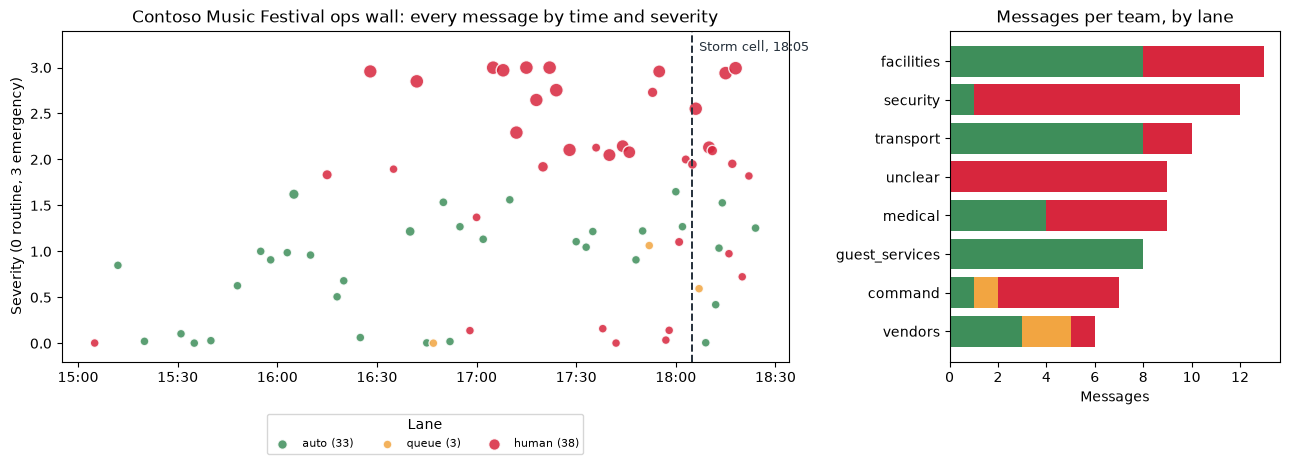

Saved output/ops-wall.png


In [15]:
LANE_COLORS = {"auto": "#3E8E5A", "queue": "#F2A541", "human": "#D7263D"}
final = shift_v2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})

for lane_name, color in LANE_COLORS.items():
    part = final[final.lane_final == lane_name]
    ax1.scatter(part.minute, part.sev, s=40 + 60 * part.danger, c=color, alpha=0.85, edgecolor="white", label=f"{lane_name} ({len(part)})")
storm = 18 * 60 + 5
ax1.axvline(storm, color="#25303B", ls="--", lw=1.4)
ax1.text(storm + 2, 3.18, "Storm cell, 18:05", fontsize=9, color="#25303B")
ax1.set_xticks(range(15 * 60, 18 * 60 + 31, 30))
ax1.set_xticklabels([f"{m // 60}:{m % 60:02d}" for m in range(15 * 60, 18 * 60 + 31, 30)])
ax1.set_ylim(-0.2, 3.4)
ax1.set_ylabel("Severity (0 routine, 3 emergency)")
ax1.set_title("Contoso Music Festival ops wall: every message by time and severity")
ax1.legend(title="Lane", loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=8, ncol=3)

by_team = pd.crosstab(final.team, final.lane_final).reindex(columns=list(LANE_COLORS), fill_value=0)
by_team = by_team.loc[by_team.sum(axis=1).sort_values().index]
left = np.zeros(len(by_team))
for lane_name, color in LANE_COLORS.items():
    ax2.barh(by_team.index, by_team[lane_name], left=left, color=color, label=lane_name)
    left += by_team[lane_name].to_numpy()
ax2.set_title("Messages per team, by lane")
ax2.set_xlabel("Messages")

plt.tight_layout()
plt.savefig(OUT_DIR / "ops-wall.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved output/ops-wall.png")

The dot size shows the danger probability. The red cluster near the top is the stretch from about 16:30 to 17:30, where most of the real emergencies arrived, and the storm brings a second wave of urgent messages after 18:05. The model does the same work throughout, and the lanes decide which messages a person sees.

## 13. Your Turn to Explore

1. Change the costs in section 10. Make a missed emergency cost 10 instead of 100, then rerun the sweeps. Which thresholds does the cost model now prefer, and would you accept them?
2. Add a fourth lane called `watch` for messages with a danger probability between 0.2 and 0.5. What does the lane table look like, and who would own that lane?
3. Rerun section 5 twice and compare the `conf` columns. How much do the probabilities move, and which messages sit close enough to a threshold to change lanes?

In [16]:
# Your experiments here

## 14. Summary

We used Microsoft-Decision-1 on a full shift at the Contoso Music Festival to:

- Check calibration by grouping decisions by confidence and measuring accuracy in each group
- Turn probabilities into three lanes, and find that a danger-only rule let real emergencies through
- Diagnose the cause from the numbers, add a severity condition, and verify that no emergency was missed
- Choose thresholds from the cost of each mistake, and replace those costs with our own
- Handle confident mistakes two ways, with a higher bar and with clearer option wording, and compare what each costs
- Put the shift on one ops wall

Reach for confidence thresholds when a decision can be automated for most cases and escalated for the rest. Check calibration on your own labeled data first, because the thresholds are only as good as the probabilities behind them. Notebook 03 puts a decision model between an agent and the world: gating its actions, checking its replies, and grading them. For background, see the [decision models primer](../../../docs/primers/decision-models.md) and the [model cards primer](../../../docs/primers/model-cards.md).

**Next steps**

- [03-guard-and-grade-the-ops-copilot.ipynb](03-guard-and-grade-the-ops-copilot.ipynb) - gate agent actions and grade replies
- [01-triage-festival-messages.ipynb](01-triage-festival-messages.ipynb) - the three question types

## 15. References

- [Deploy and use Microsoft-Decision-1 in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-microsoft-decision) - best practices for confidence thresholds and abstention
- [Microsoft-Decision-1 model card](https://ai.azure.com/catalog/models/Microsoft-Decision-1) - capabilities, intended uses, and out-of-scope uses
- [Introducing Microsoft-Decision-1 in Microsoft Foundry](https://techcommunity.microsoft.com/blog/azure-ai-foundry-blog/introducing-microsoft-decision-1-in-microsoft-foundry-for-decision-and-classific/4562742) - release context
- [Decision models primer](../../../docs/primers/decision-models.md) - what a decision API is, and how to evaluate one on our own data